In [1]:
import pandas as pd
import numpy as np
import os
import glob

def smooth_list(data, window_size):
    if not data:
        return []
    return [np.mean(data[i:i+window_size]) for i in range(0, len(data), window_size)]


## Analysis for post ratio from each opinion side

show timeseries plot of post

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
import re

# ==========================================
# 設定
# ==========================================
RESULTS_DIR = "./results"       # データのルートディレクトリ
WINDOW_SIZE = 100               # 平滑化のウィンドウサイズ
MAX_INDEX = 40000                # 読み込む最大ステップ数（Noneの場合はあるだけ読む）
BINS = ["bin_0", "bin_1", "bin_2", "bin_3", "bin_4"] # カラム名定義
# BINS = ["bin_0", "bin_1", "bin_2"]

# =========================================
# seedに基づいて実験結果ディレクトリを収集
# =========================================

all_dfs = []
run_dirs = glob.glob(os.path.join(RESULTS_DIR, "run_*"))
run_dirs = sorted(run_dirs)

# 特定のシード範囲に限定したい場合
# ========================================
SEED_TABLE = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
run_dirs = [
    os.path.join(RESULTS_DIR, f"run_{seed}_dir_0.0")
    for seed in SEED_TABLE
    if os.path.isdir(os.path.join(RESULTS_DIR, f"run_{seed}_dir_0.0"))
]
# =========================================

# 出力先
OUTPUT_DIR = "./results/pol_summary"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [3]:
def load_and_process_seed(seed_dir, seed_name):
    """
    1つのシード（run_?）フォルダ内の post データを読み込み、平滑化してDataFrameを返す
    """
    post_dir = os.path.join(seed_dir, 'posts')
    if not os.path.exists(post_dir):
        print(f'Skipping {seed_name}: post folder not found.')
        return None

    files = glob.glob(os.path.join(post_dir, 'post_result_*.csv'))
    if not files: return None
    
    dfs = []
    for f in files:
        try:
            dfs.append(pd.read_csv(f))
        except: pass
    if not dfs: return None
    
    df_all = pd.concat(dfs, ignore_index=True).sort_values('step')
    if MAX_INDEX is not None:
        df_all = df_all[df_all['step'] <= MAX_INDEX]

    ratios = {b: [] for b in BINS}
    counts = []
    steps = []

    for _, row in df_all.iterrows():
        if 'sumOfPosts' in row:
            total_posts = int(row['sumOfPosts'])
        else:
            total_posts = sum([int(row.get(b, 0)) for b in BINS])
        
        if total_posts > 0:
            for b in BINS:
                ratios[b].append(int(row.get(b, 0)) / total_posts)
        else:
            for b in BINS:
                ratios[b].append(0.0)

        counts.append(total_posts)
        steps.append(int(row['step']))

    if not steps: return None

    smoothed_steps = steps[::WINDOW_SIZE]
    data = {'step': smoothed_steps}
    for b in BINS:
        data[b] = smooth_list(ratios[b], WINDOW_SIZE)
    data['sumOfPosts'] = smooth_list(counts, WINDOW_SIZE)
    
    min_len = min([len(v) for v in data.values()])
    for k in data.keys(): data[k] = data[k][:min_len]

    df_seed = pd.DataFrame(data)
    df_seed['seed'] = seed_name
    return df_seed


Found 10 seed directories.
Processing directory: ./results/run_0_dir_0.0
Processed run_0_dir_0.0, data shape: (401, 8)
Processing directory: ./results/run_1_dir_0.0
Processed run_1_dir_0.0, data shape: (401, 8)
Processing directory: ./results/run_2_dir_0.0
Processed run_2_dir_0.0, data shape: (401, 8)
Processing directory: ./results/run_3_dir_0.0
Processed run_3_dir_0.0, data shape: (401, 8)
Processing directory: ./results/run_4_dir_0.0
Processed run_4_dir_0.0, data shape: (401, 8)
Processing directory: ./results/run_5_dir_0.0
Processed run_5_dir_0.0, data shape: (401, 8)
Processing directory: ./results/run_6_dir_0.0
Processed run_6_dir_0.0, data shape: (401, 8)
Processing directory: ./results/run_7_dir_0.0
Processed run_7_dir_0.0, data shape: (401, 8)
Processing directory: ./results/run_8_dir_0.0
Processed run_8_dir_0.0, data shape: (401, 8)
Processing directory: ./results/run_9_dir_0.0
Processed run_9_dir_0.0, data shape: (401, 8)
Aggregated data saved to ./results/pol_summary


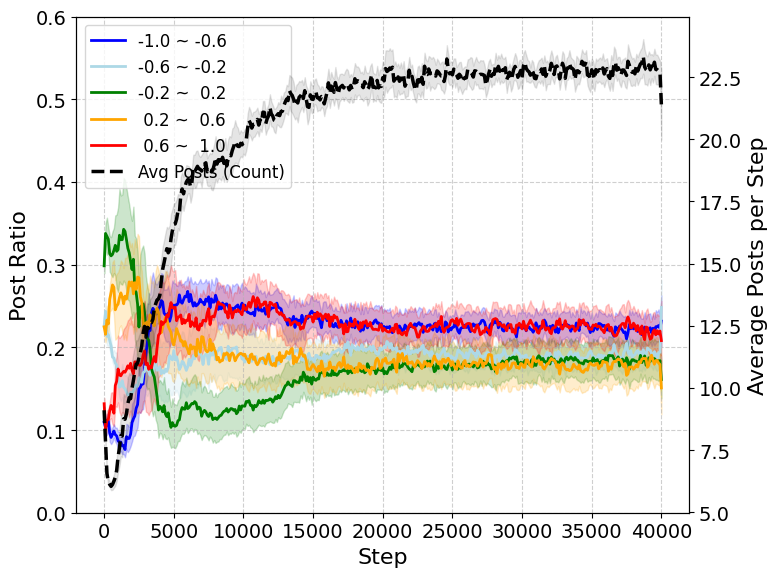

Plot generated.


In [4]:
# ==========================================
# 設定: 文字サイズなどのスタイル定義
# ==========================================
# グラフの文字サイズを全体的に大きく設定（ノートブックのスタイルに合わせる）
plt.rcParams['font.family'] = 'sans-serif'  # お好みのフォントがあれば指定
plt.rcParams['font.size'] = 14              # 基本のフォントサイズ
plt.rcParams['axes.labelsize'] = 16         # 軸ラベルのサイズ
plt.rcParams['axes.titlesize'] = 18         # タイトルのサイズ
plt.rcParams['xtick.labelsize'] = 14        # x軸目盛りのサイズ
plt.rcParams['ytick.labelsize'] = 14        # y軸目盛りのサイズ
plt.rcParams['legend.fontsize'] = 12        # 凡例のサイズ
plt.rcParams['figure.figsize'] = (8, 6)    # 画像サイズを少し大きめに

# ==========================================
# メイン処理
# ==========================================

print(f"Found {len(run_dirs)} seed directories.")

for d in run_dirs:
    print(f"Processing directory: {d}")
    seed_name = os.path.basename(d)
    # load_and_process_seed は定義済みの関数と仮定
    df = load_and_process_seed(d, seed_name)
    if df is not None:
        all_dfs.append(df)
        print(f"Processed {seed_name}, data shape: {df.shape}")

if not all_dfs:
    print("No valid data found.")
else:
    # 2. 全データを結合
    full_df = pd.concat(all_dfs, ignore_index=True)
    
    # 3. Stepごとに集計（数値列のみを対象に平均と標準誤差 SE を計算）
    # numeric_only=True を指定して文字列列のエラーを回避
    grouped = full_df.groupby("step")
    df_mean = grouped.mean(numeric_only=True)
    df_se = grouped.sem(numeric_only=True)

    # 結果をCSV保存（オプション）
    df_mean.to_csv(os.path.join(OUTPUT_DIR, "posts_mean_all_seeds.csv"))
    print(f"Aggregated data saved to {OUTPUT_DIR}")

    # ==========================================
    # プロット作成
    # ==========================================
    fig, ax1 = plt.subplots()

    steps = df_mean.index
    
    # BINSの定義（コード内で定義されていない場合はここで仮定）
    # もしBINS変数が外にある場合はそれを使ってください
    if 'BINS' not in locals():
        BINS = [f"bin_{i}" for i in range(5)]

    # --- ラベルのマッピング辞書を作成 ---
    # bin_0 ~ bin_4 を具体的な数値範囲に変換（必要に応じて数値を調整してください）
    bin_labels = {
        "bin_0": "-1.0 ~ -0.6",
        "bin_1": "-0.6 ~ -0.2",
        "bin_2": "-0.2 ~  0.2",
        "bin_3": " 0.2 ~  0.6",
        "bin_4": " 0.6 ~  1.0"
    }

    # カラーマップの設定
    BIN_COLORS = ["blue", "lightblue", "green", "orange", "red"]

    # --- 左軸: 投稿割合 (bin_0 ~ bin_4) ---
    for i, bin_name in enumerate(BINS):
        if bin_name in df_mean.columns:
            mean_val = df_mean[bin_name]
            se_val = df_se[bin_name]

            current_color = BIN_COLORS[i]
            
            # ラベルを辞書から取得（なければそのままbin名）
            label_text = bin_labels.get(bin_name, bin_name)
            
            # 平均線のプロット
            ax1.plot(steps, mean_val, label=label_text, color=current_color, linewidth=2)
            
            # 誤差範囲(SE)を塗りつぶし (帯をつける処理)
            ax1.fill_between(steps, 
                             mean_val - se_val, 
                             mean_val + se_val, 
                             color=current_color, alpha=0.2) # alphaで透明度調整

    ax1.set_xlabel("Step", fontsize=16)
    ax1.set_ylabel("Post Ratio", fontsize=16)
    ax1.set_ylim(0, 0.6)
    ax1.grid(True, linestyle="--", alpha=0.6)

    # --- 右軸: 投稿数 (sumOfPosts) ---
    # 投稿数データが存在する場合のみ描画
    if "sumOfPosts" in df_mean.columns:
        ax2 = ax1.twinx()
        
        posts_mean = df_mean["sumOfPosts"]
        posts_se = df_se["sumOfPosts"]
        
        # 投稿数は黒の点線で強調
        ax2.plot(steps, posts_mean, label="Avg Posts (Count)", color="black", linestyle="--", linewidth=2.5)
        
        # 投稿数のSE帯
        ax2.fill_between(steps, 
                         posts_mean - posts_se, 
                         posts_mean + posts_se, 
                         color="black", alpha=0.1)
        
        ax2.set_ylabel("Average Posts per Step", fontsize=16)

        # 凡例の結合 (左軸と右軸をまとめる)
        lines1, labels1 = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        # 凡例を図の左上に表示
        ax1.legend(lines1 + lines2, labels1 + labels2, bbox_to_anchor=(0, 1), loc='upper left')
    else:
        ax1.legend()

    #plt.title(f"Post Analysis (Window={WINDOW_SIZE if 'WINDOW_SIZE' in locals() else 'N/A'}, Seeds={len(all_dfs)})")
    
    # レイアウト調整（凡例が切れないように）
    plt.tight_layout()
    
    # 画像保存
    plt.savefig(os.path.join(OUTPUT_DIR, "post_analysis_plot.png"))
    plt.show()
    
    print("Plot generated.")

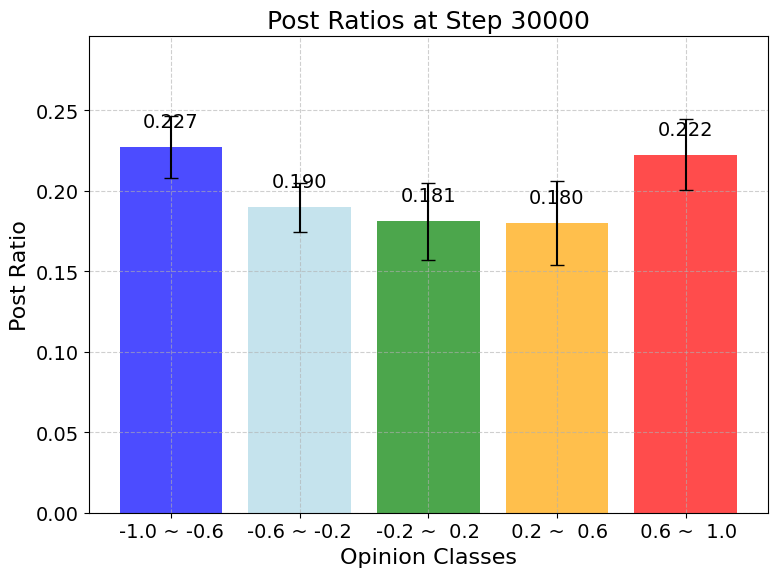

Bar plot saved to ./results/pol_summary/post_ratios_bar_step_30000.png


In [5]:
import matplotlib.pyplot as plt

# Function to plot bar graph with error bars for a specific step
def plot_post_ratios_at_step(step):
    if step not in df_mean.index:
        print(f"Step {step} not found in data.")
        return
    
    # Extract mean and SE for the step
    means = df_mean.loc[step, BINS]
    ses = df_se.loc[step, BINS]
    
    # Labels for bins
    bin_labels = {
        "bin_0": "-1.0 ~ -0.6",
        "bin_1": "-0.6 ~ -0.2",
        "bin_2": "-0.2 ~  0.2",
        "bin_3": " 0.2 ~  0.6",
        "bin_4": " 0.6 ~  1.0"
    }
    
    labels = [bin_labels.get(b, b) for b in BINS]
    colors = ["blue", "lightblue", "green", "orange", "red"]
    
    # Create bar plot
    fig, ax = plt.subplots(figsize=(8, 6))
    bars = ax.bar(labels, means, yerr=ses, capsize=5, color=colors, alpha=0.7)
    
    ax.set_xlabel("Opinion Classes")
    ax.set_ylabel("Post Ratio")
    ax.set_title(f"Post Ratios at Step {step}")
    ax.set_ylim(0, max(means + ses) * 1.2)  # y軸の上限を少し余裕を持たせる
    ax.grid(True, linestyle="--", alpha=0.6)
    
    # Add value labels on bars
    for bar, mean in zip(bars, means):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.01, f'{mean:.3f}', ha='center', va='bottom')
    
    plt.tight_layout()
    
    # Save the plot
    save_path = os.path.join(OUTPUT_DIR, f"post_ratios_bar_step_{step}.png")
    plt.savefig(save_path)
    plt.show()
    
    print(f"Bar plot saved to {save_path}")

# Example usage: plot for step 40000
plot_post_ratios_at_step(30000)

## baseline result (witout any intervention)
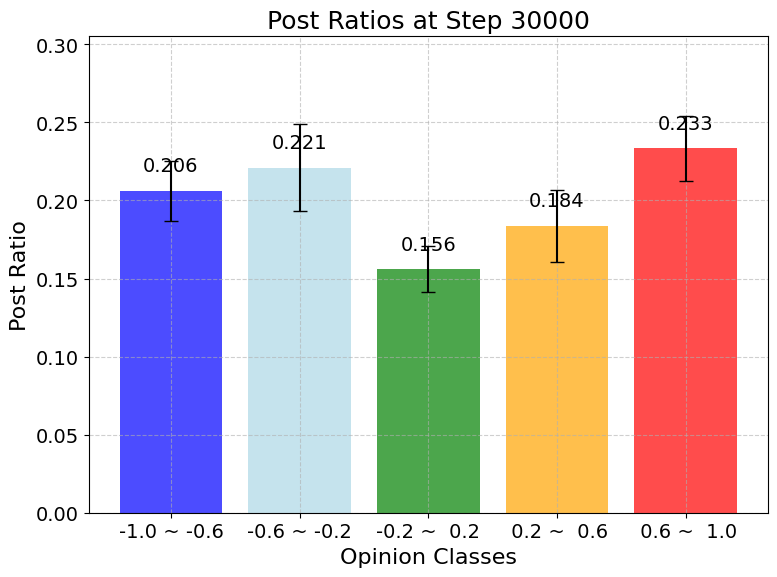

<Figure size 800x600 with 2 Axes>

In [6]:
full_df.head()

,step,bin_0,bin_1,bin_2,bin_3,bin_4,sumOfPosts,seed
0,0,0.113753,0.270467,0.313952,0.190724,0.101105,9.62,run_0_dir_0.0
1,100,0.091624,0.353144,0.279558,0.182061,0.093613,7.70,run_0_dir_0.0
2,200,0.067977,0.221275,0.343911,0.217905,0.148932,6.55,run_0_dir_0.0
3,300,0.093195,0.221544,0.309422,0.217698,0.148140,5.86,run_0_dir_0.0
4,400,0.065735,0.263355,0.321653,0.197394,0.151864,5.90,run_0_dir_0.0


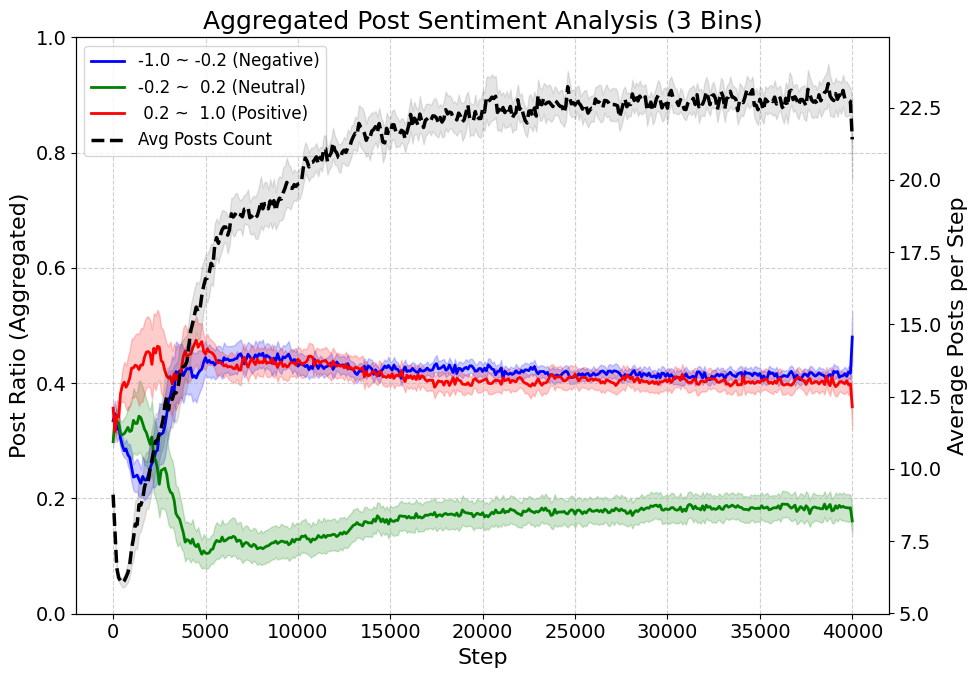

Plot generated successfully (3 bins integrated).


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# ==========================================
# 3分割統合・プロット用コード
# （Originalコードで all_dfs が作成された直後に実行することを想定）
# ==========================================

# 1. データの結合 (Originalコードですでにロードされた all_dfs を使用)
if 'all_dfs' in locals() and all_dfs:
    full_df = pd.concat(all_dfs, ignore_index=True)
    
    # --- 安全な列の統合処理 (KeyError回避) ---
    # 存在しない列を指定してもエラーにならないよう、チェックしながら足し合わせます
    
    def safe_sum(df, cols):
        """指定された列リストのうち、存在するものを足し合わせる"""
        total = 0.0
        # 少なくとも1つの列が存在するか確認するためのフラグ
        exists = False
        for c in cols:
            if c in df.columns:
                total += df[c]
                exists = True
        
        # どの列も存在しない場合は全行0のSeriesを返す（NaN回避）
        if not exists:
            return pd.Series(0.0, index=df.index)
        return total

    # 3つのカテゴリを作成
    full_df['merged_neg'] = safe_sum(full_df, ['bin_0', 'bin_1']) # -1.0 ~ -0.2
    full_df['merged_neu'] = safe_sum(full_df, ['bin_2'])          # -0.2 ~  0.2
    full_df['merged_pos'] = safe_sum(full_df, ['bin_3', 'bin_4']) #  0.2 ~  1.0

    # 2. Stepごとに集計
    grouped = full_df.groupby("step")
    df_mean = grouped.mean(numeric_only=True)
    df_se = grouped.sem(numeric_only=True)

    # ==========================================
    # プロット作成
    # ==========================================
    fig, ax1 = plt.subplots(figsize=(10, 7)) # サイズ調整

    steps = df_mean.index
    
    # プロット設定
    MERGED_BINS = ['merged_neg', 'merged_neu', 'merged_pos']
    
    bin_labels = {
        "merged_neg": "-1.0 ~ -0.2 (Negative)",
        "merged_neu": "-0.2 ~  0.2 (Neutral)",
        "merged_pos": " 0.2 ~  1.0 (Positive)"
    }
    
    BIN_COLORS = ["blue", "green", "red"]

    # --- 左軸: 投稿割合 (3分割) ---
    for i, bin_name in enumerate(MERGED_BINS):
        # 列が計算結果に含まれているか確認（safe_sumで作っているので基本はあるはずですが念のため）
        if bin_name in df_mean.columns:
            mean_val = df_mean[bin_name]
            se_val = df_se[bin_name]

            current_color = BIN_COLORS[i]
            label_text = bin_labels.get(bin_name, bin_name)
            
            # 平均線
            ax1.plot(steps, mean_val, label=label_text, color=current_color, linewidth=2)
            
            # SE帯（エラーバーの代わり）
            ax1.fill_between(steps, 
                             mean_val - se_val, 
                             mean_val + se_val, 
                             color=current_color, alpha=0.2)

    ax1.set_xlabel("Step", fontsize=16)
    ax1.set_ylabel("Post Ratio (Aggregated)", fontsize=16)
    ax1.set_ylim(0, 1.0) # 割合なので0-1固定
    ax1.grid(True, linestyle="--", alpha=0.6)
    ax1.set_title("Aggregated Post Sentiment Analysis (3 Bins)", fontsize=18)

    # --- 右軸: 投稿数 (sumOfPosts) ---
    if "sumOfPosts" in df_mean.columns:
        ax2 = ax1.twinx()
        
        posts_mean = df_mean["sumOfPosts"]
        posts_se = df_se["sumOfPosts"]
        
        ax2.plot(steps, posts_mean, label="Avg Posts Count", color="black", linestyle="--", linewidth=2.5)
        ax2.fill_between(steps, 
                         posts_mean - posts_se, 
                         posts_mean + posts_se, 
                         color="black", alpha=0.1)
        
        ax2.set_ylabel("Average Posts per Step", fontsize=16)

        # 凡例の結合
        lines1, labels1 = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax1.legend(lines1 + lines2, labels1 + labels2, bbox_to_anchor=(0, 1), loc='upper left')
    else:
        ax1.legend(loc='upper left')

    plt.tight_layout()
    
    # 保存先ディレクトリ変数がなければカレントディレクトリへ
    save_dir = OUTPUT_DIR if 'OUTPUT_DIR' in locals() else '.'
    plt.savefig(os.path.join(save_dir, "post_analysis_3bins_fixed.png"))
    plt.show()
    
    print("Plot generated successfully (3 bins integrated).")

else:
    print("Error: 'all_dfs' is not defined. Please run the data loading code first.")

## Analysis for Apparent Variance

summarize post-estimated variance and overall variance, then calculate difference of them

In [8]:
def load_single_experiment_metrics(data_dir, max_step=None):
    """
    指定ディレクトリ内の result_*.csv を全て読み込んで結合・ソートする
    """
    files = glob.glob(os.path.join(data_dir, 'result_*.csv'))
    if not files: return None

    dfs = []
    for f in files:
        try:
            dfs.append(pd.read_csv(f))
        except: pass
    
    if not dfs: return None
    
    df_all = pd.concat(dfs, ignore_index=True).sort_values('step')
    if max_step is not None:
        df_all = df_all[df_all['step'] <= max_step]
    
    return df_all


Found 10 seed directories.


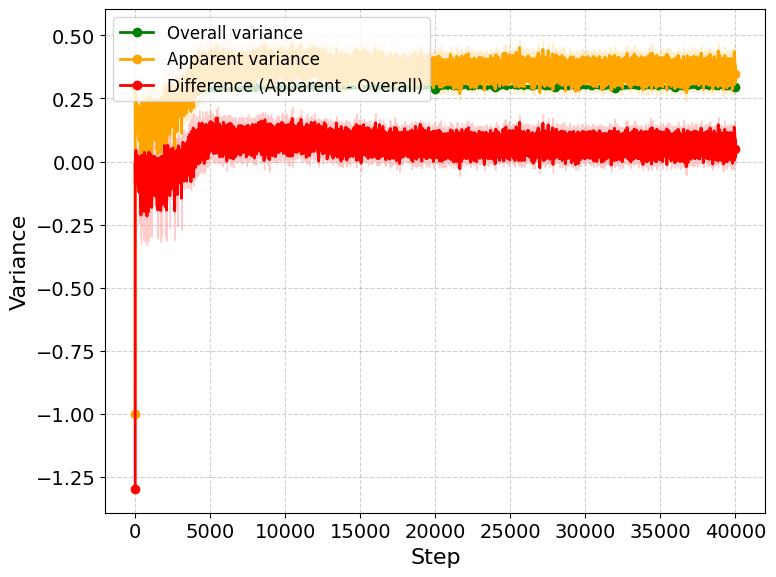


 Step-wise Variance Analysis Summary 
       opinionVar_Mean  opinionVar_SE  postOpinionVar_Mean  postOpinionVar_SE Difference_Formatted
step                                                                                              
0              0.29921        0.00216             -1.00000            0.00000   -1.29921 ± 0.00216
1000           0.22118        0.00617              0.20372            0.03434   -0.01746 ± 0.03146
2000           0.23637        0.01012              0.17568            0.03746   -0.06069 ± 0.03371
3000           0.26400        0.00941              0.21052            0.03200   -0.05348 ± 0.03036
4000           0.28022        0.00841              0.33823            0.03430    0.05801 ± 0.02833
5000           0.28632        0.00611              0.37106            0.04027     0.08474 ± 0.0362
6000           0.29149        0.00471              0.38961            0.03140    0.09812 ± 0.03017
7000           0.29538        0.00523              0.41247            

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import glob
import numpy as np

# ==========================================
# 設定: パスとスタイル
# ==========================================
RESULTS_DIR = "./results"
INPUT_FILENAME = "variance_summary.csv"
# OUTPUT_DIR is inherited from previous cells, but let's ensure it exists
if 'OUTPUT_DIR' not in locals():
    OUTPUT_DIR = "./results/pol_summary"
os.makedirs(OUTPUT_DIR, exist_ok=True)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 14
plt.rcParams['axes.labelsize'] = 16
plt.rcParams['axes.titlesize'] = 18
plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14
plt.rcParams['legend.fontsize'] = 12
plt.rcParams['figure.figsize'] = (8, 6)

def load_seed_data_robust(run_dir):
    file_path = os.path.join(run_dir, INPUT_FILENAME)
    if not os.path.exists(file_path):
        # Fallback: try to combine from metrics folder
        metrics_dir = os.path.join(run_dir, 'metrics')
        if os.path.exists(metrics_dir):
            m_files = glob.glob(os.path.join(metrics_dir, 'result_*.csv'))
            if m_files:
                dfs = [pd.read_csv(f) for f in m_files]
                df = pd.concat(dfs, ignore_index=True).sort_values('step')
                # Save it for next time
                df.to_csv(file_path, index=False)
                return df
        return None

    try:
        df = pd.read_csv(file_path)
        required = ["step", "opinionVar", "postOpinionVar"]
        if not all(col in df.columns for col in required):
            return None
        return df
    except Exception as e:
        print(f"Error reading {run_dir}: {e}")
        return None

print(f"Found {len(run_dirs)} seed directories.")
variance_dfs = []
for d in run_dirs:
    df = load_seed_data_robust(d)
    if df is not None:
        df['diffVar'] = df['postOpinionVar'] - df['opinionVar']
        variance_dfs.append(df)

if not variance_dfs:
    print("No valid variance data found.")
else:
    full_variance_df = pd.concat(variance_dfs, ignore_index=True)
    grouped = full_variance_df.groupby("step")
    df_mean = grouped.mean(numeric_only=True)
    df_se = grouped.sem(numeric_only=True)

    df_mean.to_csv(os.path.join(OUTPUT_DIR, "variance_analysis_aggregated.csv"))
    
    fig, ax = plt.subplots()
    steps = df_mean.index
    plot_config = [
        ("opinionVar",     "Overall variance",            "green"),
        ("postOpinionVar", "Apparent variance",           "orange"),
        ("diffVar",        "Difference (Apparent - Overall)", "red")
    ]
    mark_interval = max(1, int(len(steps) / 10))

    for col, label, color in plot_config:
        if col in df_mean.columns:
            mean_val = df_mean[col]
            se_val = df_se[col].fillna(0)
            ax.plot(steps, mean_val, label=label, color=color, linewidth=2, marker='o', markevery=mark_interval)
            ax.fill_between(steps, mean_val - se_val, mean_val + se_val, color=color, alpha=0.2)

    ax.set_xlabel("Step")
    ax.set_ylabel("Variance")
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend(loc="upper left")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "variance_analysis_plot.png"))
    plt.show()

    output_data = {}
    for col in ["opinionVar", "postOpinionVar", "diffVar"]:
        if col in df_mean.columns:
            output_data[f"{col}_Mean"] = df_mean[col].round(5)
            output_data[f"{col}_SE"] = df_se[col].round(5)
            if col == "diffVar":
                output_data["Difference_Formatted"] = df_mean[col].round(5).astype(str) + " ± " + df_se[col].round(5).astype(str)

    if output_data:
        df_output_summary = pd.DataFrame(output_data)
        df_filtered_summary = df_output_summary[df_output_summary.index % 1000 == 0]
        if 0 not in df_filtered_summary.index and 0 in df_output_summary.index:
            df_filtered_summary = pd.concat([df_output_summary.loc[[0]], df_filtered_summary]).sort_index()
        
        csv_output_path = os.path.join(OUTPUT_DIR, "variance_analysis_1000step_summary.csv")
        df_filtered_summary.to_csv(csv_output_path, index=True, index_label="Step")
        
        print("\n" + "=" * 60)
        print(" Step-wise Variance Analysis Summary ")
        print("=" * 60)
        display_cols = [c for c in [
            "opinionVar_Mean", "opinionVar_SE", 
            "postOpinionVar_Mean", "postOpinionVar_SE", 
            "Difference_Formatted"
        ] if c in df_filtered_summary.columns]
        if display_cols:
            print(df_filtered_summary[display_cols].to_string())
        print("=" * 60 + "\n")


In [10]:
import networkx as nx
import pandas as pd
import numpy as np
import os
import powerlaw
import matplotlib.pyplot as plt

class NetworkMetricsAnalyzer:
    """
    指定したGEXFファイルを読み込み、ネットワークの主要な統計量を計算するクラス。
    バッチ処理用に、コンソール出力を抑制する verbose オプションを追加しました。
    """
    def __init__(self, gexf_path, verbose=False):
        self.gexf_path = gexf_path
        self.metrics = {}
        self.verbose = verbose
        
        if self.verbose:
            print(f"Loading GEXF file: {self.gexf_path} ...")
            
        self.G = nx.read_gexf(gexf_path)
        
        if self.verbose:
            print("Load complete. Calculating metrics...")
            
        self._calculate_metrics()

    def _calculate_metrics(self):
        G = self.G
        is_directed = G.is_directed()
        
        num_nodes = G.number_of_nodes()
        num_edges = G.number_of_edges()
        
        degrees = [d for n, d in G.degree()]
        avg_degree = sum(degrees) / num_nodes if num_nodes > 0 else 0
        
        if is_directed:
            in_degrees = [d for n, d in G.in_degree()]
            avg_in_degree = sum(in_degrees) / num_nodes if num_nodes > 0 else 0
        else:
            avg_in_degree = np.nan
            
        G_undirected = G.to_undirected() if is_directed else G
        avg_clustering = nx.average_clustering(G_undirected)
        
        if num_nodes > 0:
            if is_directed:
                largest_cc = max(nx.weakly_connected_components(G), key=len)
            else:
                largest_cc = max(nx.connected_components(G), key=len)
            
            G_largest = G.subgraph(largest_cc).copy()
            G_largest_un = G_largest.to_undirected()
            
            try:
                avg_path_length = nx.average_shortest_path_length(G_largest_un)
                diameter = nx.diameter(G_largest_un)
            except nx.NetworkXError:
                avg_path_length = np.nan
                diameter = np.nan
        else:
            avg_path_length = np.nan
            diameter = np.nan

        try:
            communities = nx.community.louvain_communities(G_undirected)
            modularity = nx.community.modularity(G_undirected, communities)
        except Exception:
            modularity = np.nan

        try:
            valid_degrees = [d for _, d in G.in_degree() if d > 0]
            if len(valid_degrees) > 0:    
                fit = powerlaw.Fit(valid_degrees, discrete=True, verbose=False)
                gamma = fit.power_law.alpha
            else:
                gamma = np.nan
        except Exception:
            gamma = np.nan

        self.metrics = {
            "Is Directed": is_directed,
            "Number of Nodes": num_nodes,
            "Number of Edges": num_edges,
            "Average Degree": avg_degree,
            "Average In-Degree": avg_in_degree,
            "Average Clustering Coefficient": avg_clustering,
            "Average Path Length (Largest CC)": avg_path_length,
            "Network Diameter (Largest CC)": diameter,
            "Modularity (Louvain)": modularity,
            "Power-law Exponent (Gamma)": gamma
        }

# ==========================================
# バッチ処理・集計・図示の実行部
# ==========================================
if __name__ == "__main__":
    # --- 設定項目 ---
    TARGET_STEPS = list(range(0, 40001, 5000)) # 0, 5000, 10000 ... 40000
    
    # ファイルパスのテンプレート (環境に合わせて変更してください)
    BASE_DIR = "./results"
    RUN_SUFFIX = "dir_0.0"
    LAMBDA_DIR = "lambda_0.0"
    #OUTPUT_DIR = "./results/pol_summary" # 集計結果とプロットの保存先
    
    OUTPUT_CSV = os.path.join(OUTPUT_DIR, "compiled_network_metrics_agg.csv") # 集計結果のCSV
    PLOT_DIR = os.path.join(OUTPUT_DIR, "nw_plots")
    os.makedirs(PLOT_DIR, exist_ok=True)

    all_records = []

    print("=== ネットワーク指標の抽出を開始します ===")
    for step in TARGET_STEPS:
        for seed in SEED_TABLE:
            run_dir_name = f"run_{seed}_{RUN_SUFFIX}"
            gexf_path = os.path.join(BASE_DIR, run_dir_name, "GEXF", LAMBDA_DIR, f"step_{step}.gexf")
            
            if os.path.exists(gexf_path):
                print(f"Processing: Seed={seed}, Step={step}...")
                try:
                    # 前半で定義したクラスを呼び出し
                    analyzer = NetworkMetricsAnalyzer(gexf_path, verbose=False)
                    record = analyzer.metrics.copy()
                    record["Seed"] = seed
                    record["Step"] = step
                    all_records.append(record)
                except Exception as e:
                    print(f"Error processing {gexf_path}: {e}")
            else:
                print(f"File not found, skipping: {gexf_path}")

    # --- データ集計 (平均と標準偏差) ---
    raw_df = pd.DataFrame(all_records)
    if raw_df.empty:
        print("データが取得できませんでした。パスや設定を確認してください。")
        exit()

    # 数値データのみを抽出してStepごとにグループ化し、平均と標準偏差を計算
    numeric_cols = raw_df.select_dtypes(include=[np.number]).columns.tolist()
    if 'Seed' in numeric_cols:
        numeric_cols.remove('Seed') # Seed自体の平均・標準偏差は不要なので除外
    if 'Step' in numeric_cols:
        numeric_cols.remove('Step')

    print("=== データの集計を行っています ===")
    # Stepをキーにして各指標の mean と std を算出
    agg_df = raw_df.groupby('Step')[numeric_cols].agg(['mean', 'std'])
    
    # マルチインデックスになっているカラム名（例: ('Average Degree', 'mean')）を平坦化
    agg_df.columns = [f"{col[0]}_{col[1]}" for col in agg_df.columns]
    agg_df = agg_df.reset_index()

    # 集計結果をCSVに保存
    agg_df.to_csv(OUTPUT_CSV, index=False, encoding='utf-8-sig')
    print(f"=== 集計データ(平均・標準偏差)を {OUTPUT_CSV} に保存しました ===")

    # --- 時系列プロットの作成 ---
    metrics_to_plot = [
        "Number of Nodes",
        "Number of Edges",
        "Average Degree",
        "Average Clustering Coefficient",
        "Average Path Length (Largest CC)",
        "Modularity (Louvain)",
        "Power-law Exponent (Gamma)"
    ]

    print("=== 時系列プロットの生成を開始します ===")
    for metric in metrics_to_plot:
        mean_col = f"{metric}_mean"
        std_col = f"{metric}_std"
        
        # 該当する指標の列が存在するか確認
        if mean_col not in agg_df.columns:
            continue
            
        plt.figure(figsize=(8, 5))
        
        # 集計済みデータフレームからプロット
        plt.plot(agg_df['Step'], agg_df[mean_col], label='Mean', color='b', marker='o')
        
        std_values = agg_df[std_col].fillna(0)
        plt.fill_between(
            agg_df['Step'], 
            agg_df[mean_col] - std_values, 
            agg_df[mean_col] + std_values, 
            color='b', alpha=0.2, label='± 1 Std Dev'
        )
        
        plt.title(f"{metric} over Time")
        plt.xlabel("Step")
        plt.ylabel(metric)
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.legend()
        plt.tight_layout()
        
        # ファイル名に使えない文字を置換して保存
        safe_name = metric.replace(" ", "_").replace("(", "").replace(")", "")
        plot_path = os.path.join(PLOT_DIR, f"{safe_name}.png")
        plt.savefig(plot_path)
        plt.close()
        print(f"Saved plot: {plot_path}")

    print("=== 全ての処理が完了しました ===")

=== ネットワーク指標の抽出を開始します ===
Processing: Seed=0, Step=0...
Processing: Seed=1, Step=0...
Processing: Seed=2, Step=0...
Processing: Seed=3, Step=0...
Processing: Seed=4, Step=0...
Processing: Seed=5, Step=0...
Processing: Seed=6, Step=0...
Processing: Seed=7, Step=0...
Processing: Seed=8, Step=0...
Processing: Seed=9, Step=0...
Processing: Seed=0, Step=5000...
Processing: Seed=1, Step=5000...
Processing: Seed=2, Step=5000...
Processing: Seed=3, Step=5000...
Processing: Seed=4, Step=5000...
Processing: Seed=5, Step=5000...
Processing: Seed=6, Step=5000...
Processing: Seed=7, Step=5000...
Processing: Seed=8, Step=5000...
Processing: Seed=9, Step=5000...
Processing: Seed=0, Step=10000...
Processing: Seed=1, Step=10000...
Processing: Seed=2, Step=10000...
Processing: Seed=3, Step=10000...
Processing: Seed=4, Step=10000...
Processing: Seed=5, Step=10000...
Processing: Seed=6, Step=10000...
Processing: Seed=7, Step=10000...
Processing: Seed=8, Step=10000...
Processing: Seed=9, Step=10000...
Proc

In [11]:
import networkx as nx
import pandas as pd
import numpy as np
import os
import powerlaw
import matplotlib.pyplot as plt
from collections import defaultdict

# ==========================================
# 設定項目
# ==========================================
SEED_TABLE = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]  # 対象のシード値
TARGET_STEPS = [0, 20000, 40000]             # 対象のステップ

BASE_DIR = "./results"
RUN_SUFFIX = "dir_0.0" # 環境に合わせて変更
LAMBDA_DIR = "lambda_0.0" # 環境に合わせて変更
OUTPUT_DIR = "./results/pol_summary" 

OUTPUT_CSV = os.path.join(OUTPUT_DIR, "indegree_powerlaw_alpha_by_class.csv")
PLOT_DIR = os.path.join(OUTPUT_DIR, "indegree_distributions")
os.makedirs(PLOT_DIR, exist_ok=True)

# クラスごとのカラー設定（前回の設定を踏襲）
CLASS_COLORS = {
    0: "blue",
    1: "lightblue",
    2: "green",
    3: "orange",
    4: "red"
}

def get_node_class(G, node):
    """
    ノードから opinionclass を安全に取得。
    大文字・小文字の違い（opinionclass, opinionClass など）を吸収します。
    """
    attrs = G.nodes[node]
    for key, val in attrs.items():
        if str(key).lower() == 'opinionclass':
            try:
                return int(float(val))
            except (ValueError, TypeError):
                return None
    return None

if __name__ == "__main__":
    print("=== In-degree分布の抽出とフィッティングを開始します ===")
    
    alpha_records = []

    for step in TARGET_STEPS:
        print(f"\n--- Processing Step: {step} ---")
        
        # グラフ描画用に、シードごとの次数カウントを保持するデータ構造
        # class_degree_counts[op_class][seed][degree] = count
        class_degree_counts = defaultdict(lambda: defaultdict(lambda: defaultdict(int)))
        
        for seed in SEED_TABLE:
            run_dir_name = f"run_{seed}_{RUN_SUFFIX}"
            gexf_path = os.path.join(BASE_DIR, run_dir_name, "GEXF", LAMBDA_DIR, f"step_{step}.gexf")
            
            if not os.path.exists(gexf_path):
                print(f"File not found, skipping: {gexf_path}")
                continue
                
            print(f"  Loading Seed={seed}...")
            try:
                G = nx.read_gexf(gexf_path)
            except Exception as e:
                print(f"  Error reading {gexf_path}: {e}")
                continue
                
            is_directed = G.is_directed()
            
            # クラスごとに In-degree を収集
            class_indegrees = defaultdict(list)
            for n in G.nodes():
                op_class = get_node_class(G, n)
                if op_class is None:
                    continue
                
                degree = G.in_degree(n) if is_directed else G.degree(n)
                class_indegrees[op_class].append(degree)
                class_degree_counts[op_class][seed][degree] += 1

            # クラスごとに powerlaw fit を実行
            for op_class, degrees in class_indegrees.items():
                # べき乗則は k > 0 で計算するため 0 を除外
                valid_degrees = [d for d in degrees if d > 0]
                
                alpha_val = np.nan
                if len(valid_degrees) > 5: # データ数が少なすぎるとエラーになるため閾値を設定
                    try:
                        # verbose=False で標準出力を抑制
                        fit = powerlaw.Fit(valid_degrees, discrete=True, verbose=False)
                        alpha_val = fit.power_law.alpha
                    except Exception as e:
                        pass
                
                alpha_records.append({
                    "Step": step,
                    "Seed": seed,
                    "OpinionClass": op_class,
                    "Alpha": alpha_val
                })

        # --- ステップごとの In-degree 分布グラフを描画 ---
        plt.figure(figsize=(10, 7))
        
        # 存在するクラスを取得してソート（0, 1, 2, 3, 4...）
        available_classes = sorted(class_degree_counts.keys())
        
        for op_class in available_classes:
            # グラフ用のデータ集計：各次数における、全シードでの平均人数を計算
            all_degrees = set()
            for seed_counts in class_degree_counts[op_class].values():
                all_degrees.update(seed_counts.keys())
            
            x_degrees = []
            y_avg_counts = []
            
            for deg in sorted(all_degrees):
                if deg == 0:
                    continue # Log-Logグラフでは0は描画できないため除外
                
                # 指定した次数のカウントを全シードから取得（存在しないシードは0）
                counts = [class_degree_counts[op_class][seed].get(deg, 0) for seed in SEED_TABLE]
                avg_count = np.mean(counts)
                
                if avg_count > 0:
                    x_degrees.append(deg)
                    y_avg_counts.append(avg_count)
            
            color = CLASS_COLORS.get(op_class, "black")
            label = f"Class {op_class}"
            
            # 散布図でプロット（線で結ばない方が度数分布は見やすい）
            plt.scatter(x_degrees, y_avg_counts, color=color, label=label, alpha=0.7, s=20)

        plt.title(f"In-Degree Distribution by Opinion Class (Step {step})")
        plt.xlabel("In-Degree (k_in)")
        plt.ylabel("Number of Nodes (Count)")
        plt.xscale('log') # べき乗則を見るため両対数グラフにする
        plt.yscale('log')
        plt.grid(True, which="both", ls="--", alpha=0.3)
        plt.legend()
        
        plot_path = os.path.join(PLOT_DIR, f"indegree_dist_step_{step}.png")
        plt.savefig(plot_path)
        plt.close()
        print(f"  -> Saved plot for Step {step} to {plot_path}")

    # --- CSVへの集計と保存 ---
    print("\n=== 係数データの集計を行っています ===")
    df_alpha = pd.DataFrame(alpha_records)
    
    if not df_alpha.empty:
        # StepとOpinionClassでグループ化し、Alphaの平均と標準偏差を計算
        agg_alpha = df_alpha.groupby(['Step', 'OpinionClass'])['Alpha'].agg(['mean', 'std']).reset_index()
        agg_alpha.rename(columns={'mean': 'Alpha_mean', 'std': 'Alpha_std'}, inplace=True)
        
        agg_alpha.to_csv(OUTPUT_CSV, index=False, encoding='utf-8-sig')
        print(f"=== べき指数の集計データを {OUTPUT_CSV} に保存しました ===")
    else:
        print("出力可能なべき指数のデータがありませんでした。")

    print("=== \u5168\u3066\u306e\u51e6\u7406\u304c\u5b8c\u4e86\u3057\u307e\u3057\u305f ===")

=== In-degree分布の抽出とフィッティングを開始します ===

--- Processing Step: 0 ---
  Loading Seed=0...
  Loading Seed=1...
  Loading Seed=2...
  Loading Seed=3...
  Loading Seed=4...
  Loading Seed=5...
  Loading Seed=6...
  Loading Seed=7...
  Loading Seed=8...
  Loading Seed=9...
  -> Saved plot for Step 0 to ./results/pol_summary/indegree_distributions/indegree_dist_step_0.png

--- Processing Step: 20000 ---
  Loading Seed=0...
  Loading Seed=1...
  Loading Seed=2...
  Loading Seed=3...
  Loading Seed=4...
  Loading Seed=5...
  Loading Seed=6...
  Loading Seed=7...
  Loading Seed=8...
  Loading Seed=9...
  -> Saved plot for Step 20000 to ./results/pol_summary/indegree_distributions/indegree_dist_step_20000.png

--- Processing Step: 40000 ---
  Loading Seed=0...
  Loading Seed=1...
  Loading Seed=2...
  Loading Seed=3...
  Loading Seed=4...
  Loading Seed=5...
  Loading Seed=6...
  Loading Seed=7...
  Loading Seed=8...
  Loading Seed=9...
  -> Saved plot for Step 40000 to ./results/pol_summary/indegre

## Network Index Evolution Analysis

This section calculates the evolution of network indices according to the directed graph formulations defined in `docs/tasks/network-index-report.html`.

### Indices Calculated:
1. **Density**: $m / (n(n-1))$
2. **Average Clustering**: Fagiolo (2007) directed clustering coefficient.
3. **Power-law Exponent ($\gamma$)**: MLE estimator on in-degree sequence (Clauset et al., 2009).
4. **Modularity Q**: Leicht-Newman directed modularity, using Louvain partitions from undirected projection.
5. **Average In-degree**: Mean follower count across all nodes.
6. **Average Betweenness Centrality**: Based on directed shortest paths.
7. **Average PageRank**: Asymmetric diffusion score ($\alpha=0.85$).
8. **Average Eigenvector Centrality**: Left eigenvector (authority/prestige score).

Results are aggregated across seeds to show the mean and standard error (SE) band.

In [12]:
import networkx as nx
import pandas as pd
import numpy as np
import os
import powerlaw
import matplotlib.pyplot as plt

class RefinedNetworkMetricsAnalyzer:
    """
    Network metrics calculation according to directed graph formulations
    as specified in docs/tasks/network-index-report.html.
    """
    def __init__(self, G):
        self.G = G
        self.is_directed = G.is_directed()
        self.n = G.number_of_nodes()
        self.m = G.number_of_edges()

    def calculate_all(self):
        metrics = {}
        G = self.G
        
        if self.n == 0:
            return {k: np.nan for k in ['Density', 'Avg_Clustering', 'Gamma', 'Modularity', 
                                       'Avg_InDegree', 'Avg_Betweenness', 'Avg_PageRank', 'Avg_Eigenvector']}

        # 1. Density: m / (n * (n-1)) for directed
        metrics['Density'] = nx.density(G)
        
        # 2. Average Clustering (Fagiolo 2007 formula for DiGraph)
        metrics['Avg_Clustering'] = nx.average_clustering(G)
        
        # 3. Power-law Exponent Gamma (Clauset et al. 2009 on in-degree)
        in_degrees = [d for n, d in G.in_degree()]
        valid_in_degrees = [d for d in in_degrees if d > 0]
        if len(valid_in_degrees) > 10:
            try:
                fit = powerlaw.Fit(valid_in_degrees, discrete=True, verbose=False)
                metrics['Gamma'] = fit.power_law.alpha
            except:
                metrics['Gamma'] = np.nan
        else:
            metrics['Gamma'] = np.nan
            
        # 4. Modularity Q (Two-step directed procedure: Leicht & Newman 2008)
        try:
            G_und = G.to_undirected()
            try:
                communities = nx.community.louvain_communities(G_und, seed=42)
            except AttributeError:
                communities = list(nx.community.greedy_modularity_communities(G_und))
            
            metrics['Modularity'] = nx.community.modularity(G, communities)
        except:
            metrics['Modularity'] = np.nan
            
        # 5. Average In-degree (m/n)
        metrics['Avg_InDegree'] = np.mean(in_degrees) if in_degrees else np.nan
        
        # 6. Betweenness Centrality (Average)
        try:
            bc = nx.betweenness_centrality(G, normalized=True)
            metrics['Avg_Betweenness'] = np.mean(list(bc.values()))
        except:
            metrics['Avg_Betweenness'] = np.nan
            
        # 7. PageRank (Average)
        try:
            pr = nx.pagerank(G, alpha=0.85, max_iter=200)
            metrics['Avg_PageRank'] = np.mean(list(pr.values()))
        except:
            metrics['Avg_PageRank'] = np.nan
            
        # 8. Eigenvector Centrality (Average, Left Eigenvector)
        try:
            ec = nx.eigenvector_centrality(G, max_iter=1000, tol=1e-6)
            metrics['Avg_Eigenvector'] = np.mean(list(ec.values()))
        except:
            metrics['Avg_Eigenvector'] = np.nan
            
        return metrics


In [13]:
TARGET_STEPS = [0, 10000, 20000, 30000, 40000]
SEED_TABLE = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
BASE_DIR = "./results"
RUN_SUFFIX = "dir_0.0"
LAMBDA_DIR = "lambda_0.0"
OUTPUT_DIR = "./results/pol_summary"
os.makedirs(OUTPUT_DIR, exist_ok=True)

results = []

for step in TARGET_STEPS:
    print(f"Processing Step: {step}")
    for seed in SEED_TABLE:
        run_dir_name = f"run_{seed}_{RUN_SUFFIX}"
        gexf_path = os.path.join(BASE_DIR, run_dir_name, "GEXF", LAMBDA_DIR, f"step_{step}.gexf")
        
        if os.path.exists(gexf_path):
            try:
                G = nx.read_gexf(gexf_path)
                analyzer = RefinedNetworkMetricsAnalyzer(G)
                metrics = analyzer.calculate_all()
                metrics['step'] = step
                metrics['seed'] = seed
                results.append(metrics)
                print(f"  Seed {seed} complete.")
            except Exception as e:
                print(f"  Error Seed {seed}: {e}")

df_results = pd.DataFrame(results)
df_results.to_csv(os.path.join(OUTPUT_DIR, "network_index_evolution.csv"), index=False)
print("Analysis complete and saved.")


Processing Step: 0
  Seed 0 complete.
  Seed 1 complete.
  Seed 2 complete.
  Seed 3 complete.
  Seed 4 complete.
  Seed 5 complete.
  Seed 6 complete.
  Seed 7 complete.
  Seed 8 complete.
  Seed 9 complete.
Processing Step: 10000
  Seed 0 complete.
  Seed 1 complete.
  Seed 2 complete.
  Seed 3 complete.
  Seed 4 complete.
  Seed 5 complete.
  Seed 6 complete.
  Seed 7 complete.
  Seed 8 complete.
  Seed 9 complete.
Processing Step: 20000
  Seed 0 complete.
  Seed 1 complete.
  Seed 2 complete.
  Seed 3 complete.
  Seed 4 complete.
  Seed 5 complete.
  Seed 6 complete.
  Seed 7 complete.
  Seed 8 complete.
  Seed 9 complete.
Processing Step: 30000
  Seed 0 complete.
  Seed 1 complete.
  Seed 2 complete.
  Seed 3 complete.
  Seed 4 complete.
  Seed 5 complete.
  Seed 6 complete.
  Seed 7 complete.
  Seed 8 complete.


  Seed 9 complete.
Processing Step: 40000
  Seed 0 complete.
  Seed 1 complete.
  Seed 2 complete.
  Seed 3 complete.
  Seed 4 complete.
  Seed 5 complete.
  Seed 6 complete.
  Seed 7 complete.
  Seed 8 complete.
  Seed 9 complete.
Analysis complete and saved.


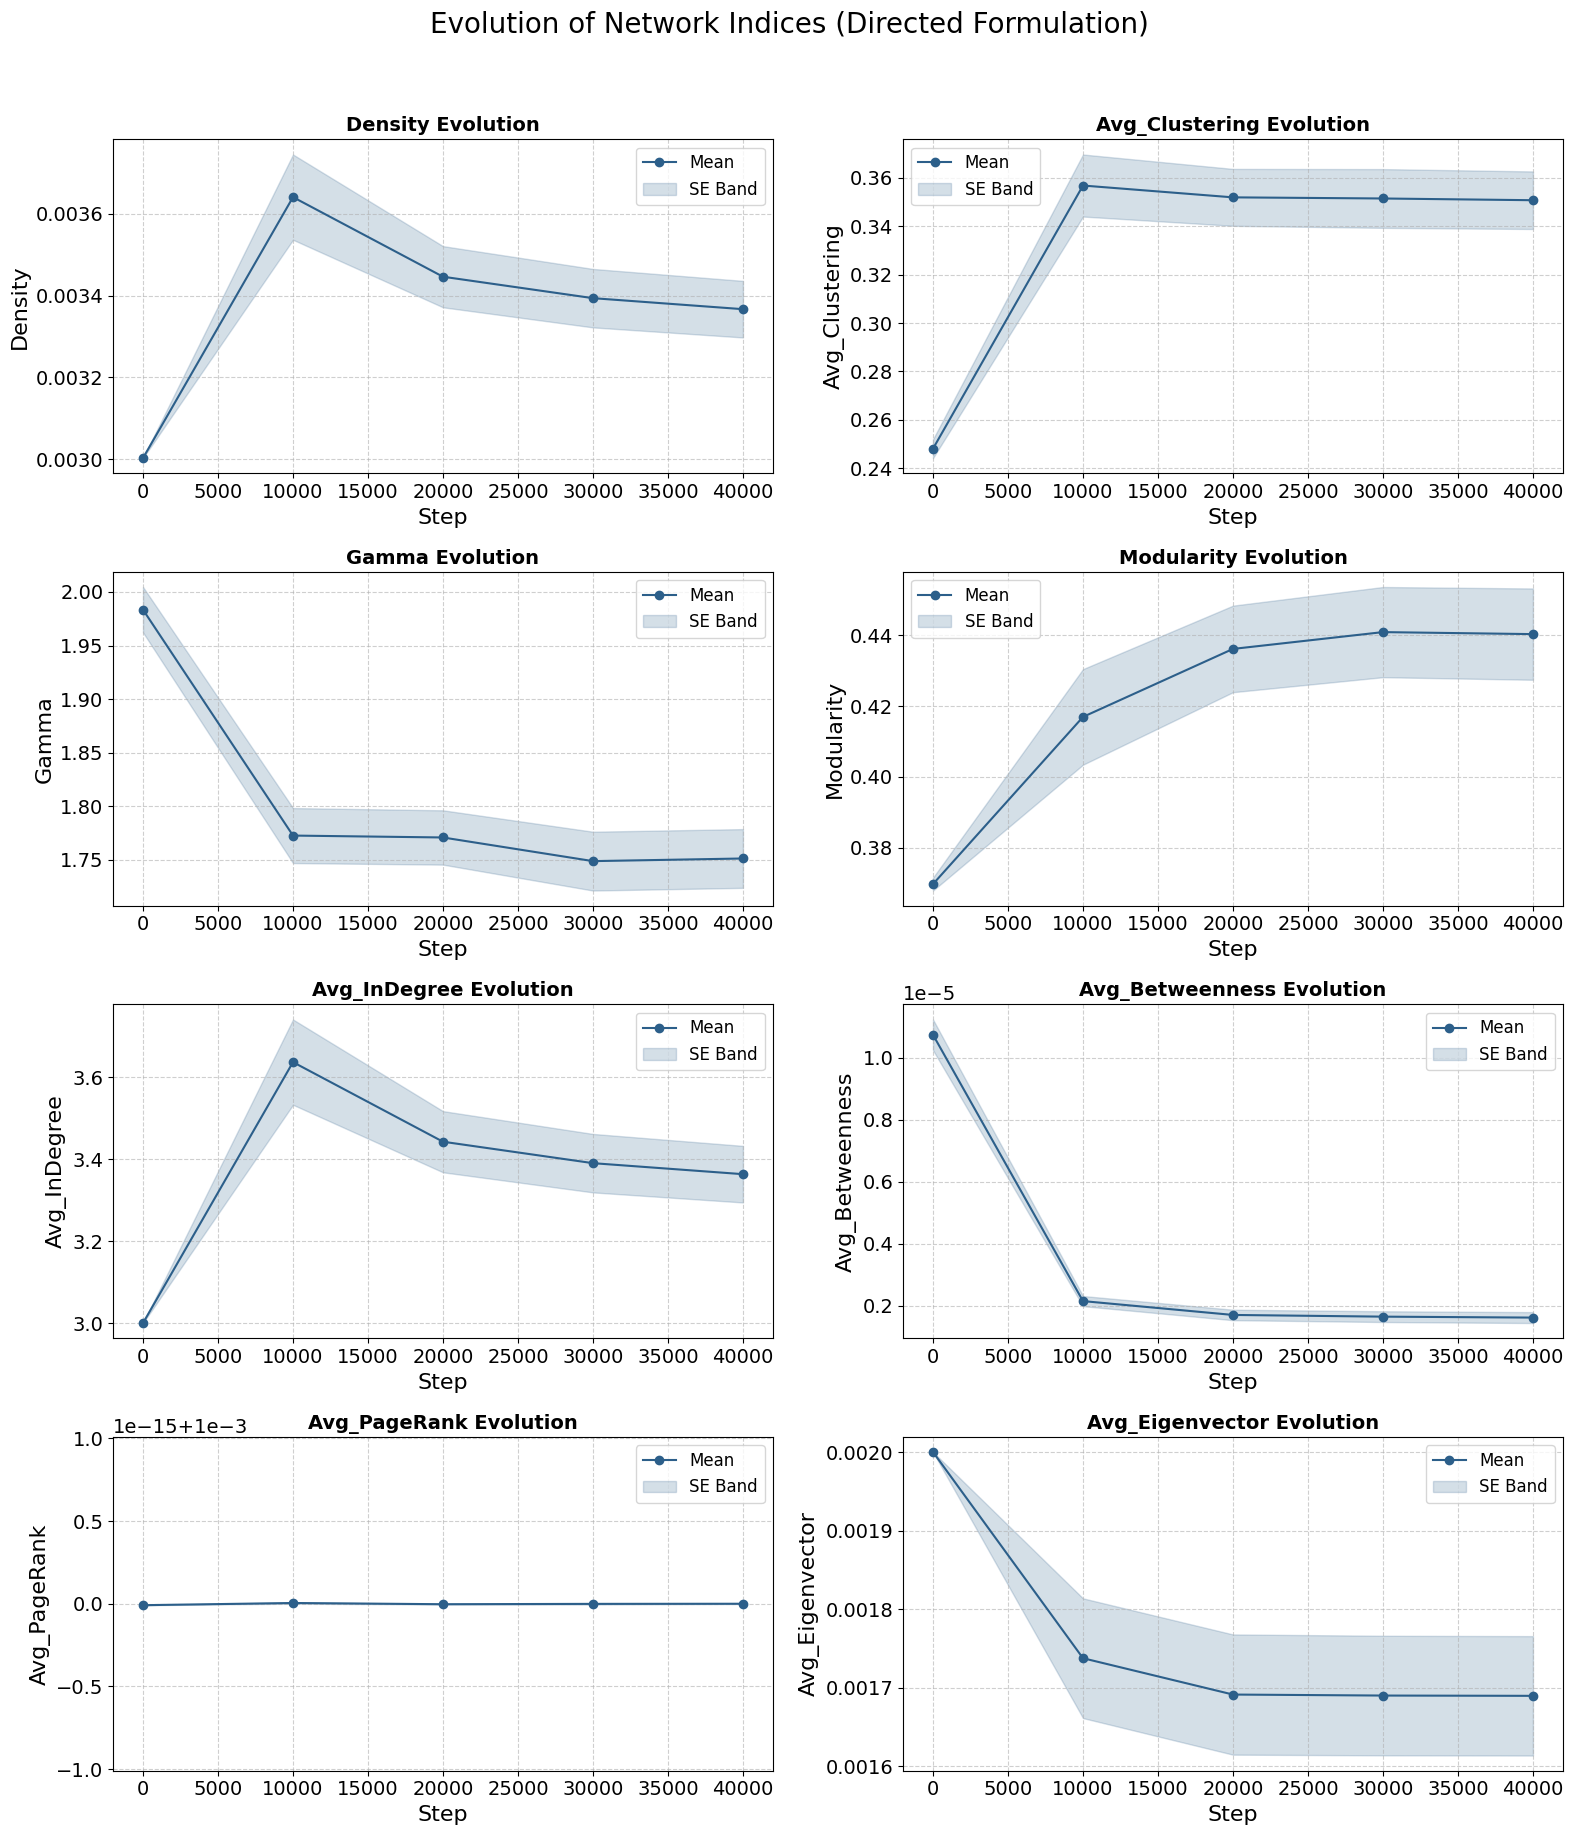

In [14]:
# Plotting the evolution with SE bands
metrics_to_plot = [
    'Density', 'Avg_Clustering', 'Gamma', 'Modularity', 
    'Avg_InDegree', 'Avg_Betweenness', 'Avg_PageRank', 'Avg_Eigenvector'
]

grouped = df_results.groupby('step')
df_mean = grouped.mean(numeric_only=True)
df_se = grouped.sem(numeric_only=True)

plt.figure(figsize=(16, 18))
plt.suptitle("Evolution of Network Indices (Directed Formulation)", fontsize=20, y=1.02)

for i, metric in enumerate(metrics_to_plot):
    plt.subplot(4, 2, i+1)
    x = df_mean.index
    y = df_mean[metric]
    se = df_se[metric]
    
    plt.plot(x, y, marker='o', color='#2c5f8a', label='Mean')
    plt.fill_between(x, y - se, y + se, color='#2c5f8a', alpha=0.2, label='SE Band')
    
    plt.title(f"{metric} Evolution", fontsize=14, fontweight='bold')
    plt.xlabel("Step")
    plt.ylabel(metric)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "network_index_evolution.png"), bbox_inches='tight')
plt.show()
